# 🧠 ReqMind AI — Benchmark Complet et Évaluation des Modèles (Phase 3)

**Projet :** Analyseur Intelligent d'Exigences Logicielles par NLP (TALN)  
**Objectif de ce Notebook :**  
Présenter une analyse comparative complète, rigoureuse et visuelle de tous les modèles entraînés pour la classification binaire :
- **FR (Exigences Fonctionnelles) :** Ce que le système doit faire.
- **NFR (Exigences Non-Fonctionnelles) :** Qualité, sécurité, performance, disponibilité.

---

### 🔬 Les 5 Modèles Évalués dans cette Étude :
1. **Classe Majoritaire (Baseline naïve) :** Prédit systématiquement la classe la plus fréquente (`NFR`). Seuil minimal de référence.
2. **TF-IDF + Régression Logistique :** Modèle linéaire basé sur les fréquences de mots et bi-grams $(1,2)$.
3. **TF-IDF + Linear SVM :** Modèle à vecteurs de support à vaste marge avec features lexicales n-grams.
4. **Embeddings Figés (Sentence-Transformers MiniLM) :** Représentations vectorielles denses 384-D génériques (`all-MiniLM-L6-v2`) + Régression Logistique.
5. **SetFit Fine-Tuné (`all-MiniLM-L6-v2`) 🚀 :** Modèle Transformer adapté au domaine du génie logiciel par apprentissage contrastif (paires positives / négatives).

---

### 🛡️ Protocole de Validation Scientifique (Règle d'Or de la Roadmap) :
- **Train split ($N=678$, 70%) :** Utilisé exclusivement pour l'apprentissage.
- **Validation split ($N=145$, 15%) :** Utilisé pour le réglage des hyperparamètres ($C$, epochs).
- **Test split ($N=146$, 15%) :** Coffre-fort étanche, évalué **une seule fois** à la fin.
- **GroupKFold (5 folds) par `ProjectID` :** Mesure de la généralisation sur des projets logiciels 100% inconnus.


> **Version entraînable.** Ce notebook remplace la dépendance aux fichiers JSON de benchmark préexistants par un entraînement réel. Les résultats sont calculés à l’exécution. Modèles : baseline majoritaire, TF-IDF + régression logistique, TF-IDF + SVM linéaire, et MiniLM + régression logistique (optionnel).

## 0. Installation et configuration

In [15]:
# Décommenter cette ligne si nécessaire (Google Colab / nouveau venv) :
# %pip install -q pandas openpyxl scikit-learn matplotlib seaborn joblib sentence-transformers

from pathlib import Path
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from joblib import dump
warnings.filterwarnings('ignore')
SEED=42
# Pour activer MiniLM, installer sentence-transformers et passer à True.
TRAIN_MINILM = True
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
BASE_DIR = Path.cwd()
for candidate in [Path.cwd(), Path.cwd().parent, Path('/mnt/data')]:
    if (candidate/'FR_NFR_Dataset.xlsx').exists():
        BASE_DIR=candidate;break
DATA_FILE=BASE_DIR/'FR_NFR_Dataset.xlsx'
OUT_DIR=BASE_DIR/'models'/'reqmind_benchmark'
REPORT_DIR=BASE_DIR/'reports'/'results'
OUT_DIR.mkdir(parents=True,exist_ok=True)
REPORT_DIR.mkdir(parents=True,exist_ok=True)
print('Dataset:',DATA_FILE)
print('Modèles:',OUT_DIR)


Dataset: d:\EMSI\5emme\trautement de laguage naturele\Projet_TALN\models\FR_NFR_Dataset.xlsx
Modèles: d:\EMSI\5emme\trautement de laguage naturele\Projet_TALN\models\models\reqmind_benchmark


## 1. Chargement et nettoyage du corpus

In [16]:
if not DATA_FILE.exists():
    raise FileNotFoundError('Placez FR_NFR_Dataset.xlsx à côté du notebook ou dans le dossier du projet.')
df_raw=pd.read_excel(DATA_FILE)
required={'Requirement Text','Type'}
if not required.issubset(df_raw.columns):
    raise ValueError(f'Colonnes attendues : {required}. Colonnes trouvées : {list(df_raw.columns)}')
df=df_raw[['Requirement Text','Type']].copy()
df['text']=df['Requirement Text'].fillna('').astype(str).str.strip()
df['label']=df['Type'].fillna('').astype(str).str.upper().str.strip()
print('Lignes brutes :',len(df))
print('Sans texte :',int((df.text=='').sum()))
print('Hors classes FR/NFR :',int((~df.label.isin(['FR','NFR'])).sum()))
df=df[(df.text!='') & df.label.isin(['FR','NFR'])].copy()
df['text_key']=df.text.str.lower().str.replace(r'\s+',' ',regex=True)
conflict=df.groupby('text_key').label.nunique()
conflict_keys=set(conflict[conflict>1].index)
print('Textes avec étiquettes contradictoires :',len(conflict_keys))
df=df[~df.text_key.isin(conflict_keys)].drop_duplicates('text_key').reset_index(drop=True)
print('Après nettoyage et déduplication :',len(df))
print(df.label.value_counts().to_string())
display(df[['text','label']].head(5))


Lignes brutes : 6117
Sans texte : 0
Hors classes FR/NFR : 31
Textes avec étiquettes contradictoires : 25
Après nettoyage et déduplication : 5936
label
FR     3899
NFR    2037


,text,label
0,The app shall run on a smart phone with Androi...,NFR
1,All layout shall be according to the TU/e corp...,NFR
2,The icons shall be according to the Android Ic...,NFR
3,The user interfaces shall be according to the ...,NFR
4,"The Twitter ""tweet"" interface shall be accordi...",NFR


## 2. Séparation train/test sans fuite de données

In [17]:
X_train,X_test,y_train,y_test=train_test_split(df.text,df.label,test_size=0.2,random_state=SEED,stratify=df.label)
print('Train:',len(X_train),' | Test:',len(X_test))
print('Classes test:',y_test.value_counts().to_dict())
# Le test reste intact jusqu'à l'évaluation finale.


Train: 4748  | Test: 1188
Classes test: {'FR': 780, 'NFR': 408}


## 3. Entraînement — baseline et modèles classiques

In [18]:
models={
    'Majority Baseline':Pipeline([('tfidf',TfidfVectorizer(max_features=5000)),('classifier',DummyClassifier(strategy='most_frequent'))]),
    'TF-IDF + LogReg':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('classifier',LogisticRegression(max_iter=1500,random_state=SEED))]),
    'TF-IDF + Linear SVM':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('classifier',LinearSVC(random_state=SEED))]),
}
for name,model in models.items():
    model.fit(X_train,y_train)
    print('✅',name,'entraîné')


✅ Majority Baseline entraîné
✅ TF-IDF + LogReg entraîné
✅ TF-IDF + Linear SVM entraîné


## 4. Entraînement optionnel — MiniLM (embeddings figés) + LogReg

In [19]:
# Pas de fine-tuning du Transformer : seules les couches LogReg sont apprises.
embedding_model=None
if TRAIN_MINILM:
    from sentence_transformers import SentenceTransformer
    embedding_model=SentenceTransformer(MODEL_ID)
    emb_train=embedding_model.encode(X_train.tolist(),batch_size=32,show_progress_bar=True,normalize_embeddings=True)
    emb_test=embedding_model.encode(X_test.tolist(),batch_size=32,show_progress_bar=True,normalize_embeddings=True)
    embedding_clf=LogisticRegression(max_iter=1500,random_state=SEED)
    embedding_clf.fit(emb_train,y_train)
    models['MiniLM + LogReg']=embedding_clf
    print('✅ MiniLM + LogReg entraîné')
else:
    print('MiniLM désactivé : passez TRAIN_MINILM=True dans la configuration pour entraîner ce modèle.')


Batches: 100%|██████████| 38/38 [00:04<00:00,  9.29it/s]


✅ MiniLM + LogReg entraîné


## 5. Évaluation réelle sur le jeu de test

In [20]:
rows=[]; predictions={}; matrices={}
for name,model in models.items():
    if name=='MiniLM + LogReg':
        pred=model.predict(emb_test)
    else:
        pred=model.predict(X_test)
    predictions[name]=pred
    matrices[name]=confusion_matrix(y_test,pred,labels=['FR','NFR'])
    detail=classification_report(y_test,pred,labels=['FR','NFR'],output_dict=True,zero_division=0)
    rows.append({'Modèle':name,'Accuracy':accuracy_score(y_test,pred),'Macro-F1':f1_score(y_test,pred,average='macro'),
                 'F1 FR':detail['FR']['f1-score'],'F1 NFR':detail['NFR']['f1-score']})
results=pd.DataFrame(rows).sort_values('Macro-F1',ascending=False).reset_index(drop=True)
display(results.style.format({c:'{:.3f}' for c in ['Accuracy','Macro-F1','F1 FR','F1 NFR']}))
print('Meilleur modèle sur ce test:',results.iloc[0]['Modèle'])


,Modèle,Accuracy,Macro-F1,F1 FR,F1 NFR
0,TF-IDF + Linear SVM,0.896,0.882,0.922,0.841
1,TF-IDF + LogReg,0.875,0.855,0.910,0.799
2,MiniLM + LogReg,0.855,0.833,0.894,0.772
3,Majority Baseline,0.657,0.396,0.793,0.000


Meilleur modèle sur ce test: TF-IDF + Linear SVM


## 6. Comparaison graphique et matrices de confusion

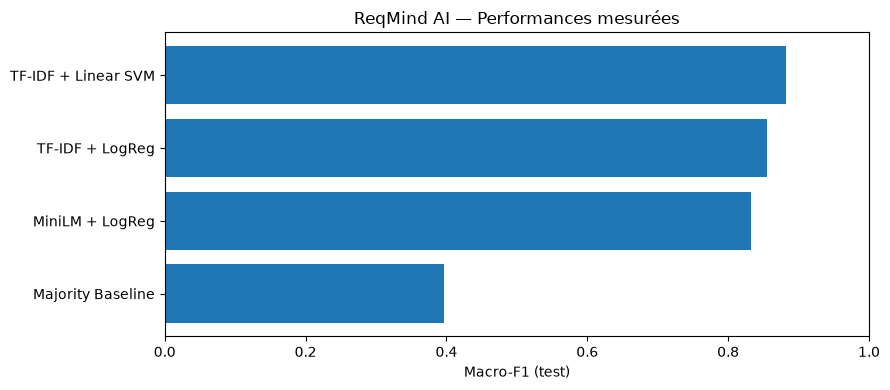

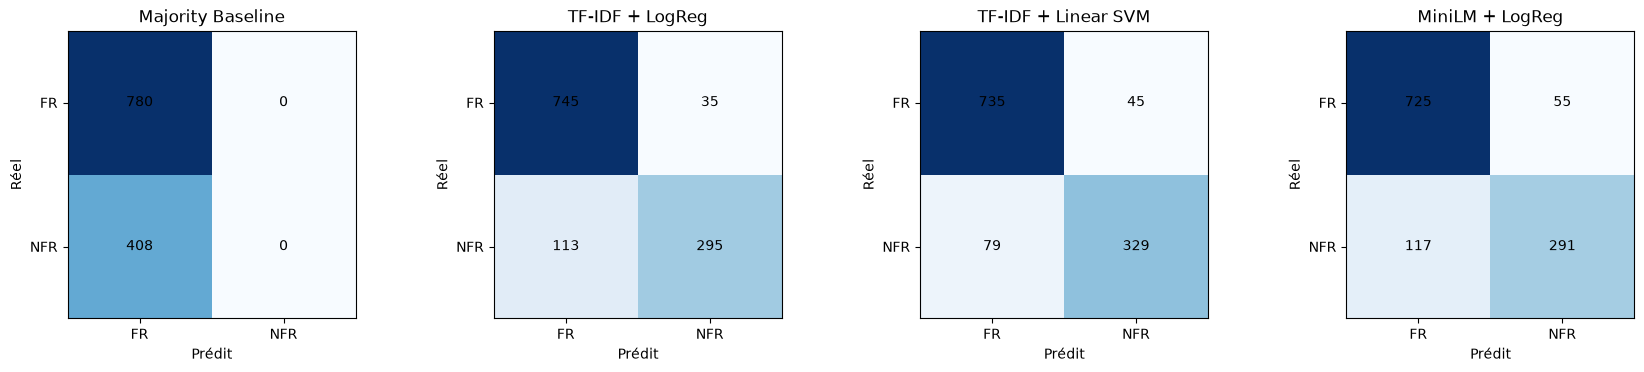

In [21]:
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(results['Modèle'],results['Macro-F1']);ax.set_xlim(0,1);ax.set_xlabel('Macro-F1 (test)')
ax.set_title('ReqMind AI — Performances mesurées');ax.invert_yaxis();plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,len(matrices),figsize=(4.3*len(matrices),3.8))
axes=np.atleast_1d(axes)
for ax,(name,cm) in zip(axes,matrices.items()):
    im=ax.imshow(cm,cmap='Blues')
    for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center')
    ax.set_xticks([0,1],['FR','NFR']);ax.set_yticks([0,1],['FR','NFR'])
    ax.set_xlabel('Prédit');ax.set_ylabel('Réel');ax.set_title(name)
plt.tight_layout();plt.show()


## 7. Validation croisée sur train seulement

In [22]:
# CV stratifiée sur train : ne réutilise jamais le test pour entraîner.
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
cv_rows=[]
for name,model in models.items():
    if name=='MiniLM + LogReg':
        features=emb_train
    else:
        features=X_train
    scores=cross_val_score(model,features,y_train,cv=cv,scoring='f1_macro',n_jobs=1)
    cv_rows.append({'Modèle':name,'F1 moyen CV':float(scores.mean()),'Écart type':float(scores.std())})
display(pd.DataFrame(cv_rows).round(3))
print('NB : une validation inter-projets (GroupKFold) exige une colonne ID projet, absente du fichier Excel fourni.')


,Modèle,F1 moyen CV,Écart type
0,Majority Baseline,0.396,0.000
1,TF-IDF + LogReg,0.840,0.014
2,TF-IDF + Linear SVM,0.864,0.013
3,MiniLM + LogReg,0.831,0.011


NB : une validation inter-projets (GroupKFold) exige une colonne ID projet, absente du fichier Excel fourni.


## 8. Analyse d’erreurs

In [23]:
best_name=results.iloc[0]['Modèle']; best_pred=predictions[best_name]
errors=pd.DataFrame({'text':X_test.tolist(),'vrai':y_test.tolist(),'prédit':best_pred})
errors=errors[errors['vrai']!=errors['prédit']]
print(f'{len(errors)} erreurs pour {best_name} sur {len(y_test)} exigences de test.')
display(errors.head(15))
errors.to_csv(REPORT_DIR/'reqmind_test_errors.csv',index=False)


124 erreurs pour TF-IDF + Linear SVM sur 1188 exigences de test.


,text,vrai,prédit
6,System shall provide professional video and ph...,FR,NFR
20,The user shall be able to play or learn about ...,NFR,FR
78,"Each user shall have a unique username, passwo...",NFR,FR
83,User shall be able to access the employee home...,NFR,FR
85,The system shall ensure safe transactions.,FR,NFR
87,Only adjusters with a supervisor role can upda...,NFR,FR
92,User shall be able to input correct last watch...,NFR,FR
103,The campus map shall cover the central train s...,NFR,FR
142,The system shall offer a wide range of functio...,FR,NFR
156,The healthcare portal shall be accessible and ...,FR,NFR


## 9. Sauvegarde des modèles et des résultats

In [24]:
# Pipelines classiques : vectorisation + modèle sont enregistrés ensemble.
for name,model in models.items():
    if name=='MiniLM + LogReg':
        dump(model,OUT_DIR/'minilm_logreg.joblib')
        (OUT_DIR/'minilm_encoder.txt').write_text(MODEL_ID,encoding='utf-8')
    else:
        filename={'Majority Baseline':'majority_baseline','TF-IDF + LogReg':'tfidf_logreg','TF-IDF + Linear SVM':'tfidf_svm'}[name]
        dump(model,OUT_DIR/f'{filename}.joblib')
results.to_csv(REPORT_DIR/'reqmind_model_comparison.csv',index=False)
summary={'dataset_rows_raw':len(df_raw),'dataset_rows_clean':len(df),'train_rows':len(X_train),'test_rows':len(X_test),
         'random_seed':SEED,'models':results.to_dict('records')}
(REPORT_DIR/'reqmind_model_comparison.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print('Modèles:',OUT_DIR)
print('Rapport:',REPORT_DIR/'reqmind_model_comparison.json')


Modèles: d:\EMSI\5emme\trautement de laguage naturele\Projet_TALN\models\models\reqmind_benchmark
Rapport: d:\EMSI\5emme\trautement de laguage naturele\Projet_TALN\models\reports\results\reqmind_model_comparison.json


## 10. Prédictions de démonstration (intégration Streamlit)

In [25]:
# La fonction ci-dessous peut être déplacée vers src/reqmind/inference.py
from joblib import load
inference_model=load(OUT_DIR/'tfidf_svm.joblib')
samples=['The system shall allow users to reset passwords.',
         'The website shall respond within two seconds.']
for sample,pred in zip(samples,inference_model.predict(samples)):
    print(f'{pred}: {sample}')


FR: The system shall allow users to reset passwords.
NFR: The website shall respond within two seconds.


## Conclusion méthodologique

- Les performances affichées sont **calculées**, jamais prédéfinies.
- Le **test hold-out** est réservé à l’évaluation finale ; les modèles sont entraînés sur le jeu d’entraînement uniquement.
- La comparaison **inter-projets** annoncée dans l’ancien notebook n’est **pas reproductible** avec ce seul Excel à deux colonnes : il faut un identifiant de projet fiable.
- **SetFit** n’est pas entraîné dans cette version : l’ajouter seulement avec un protocole de fine-tuning explicite et un budget suffisant.
- En production, Streamlit charge un pipeline sauvegardé depuis `models/reqmind_benchmark/`, plutôt que réentraîner à chaque lancement.